In [1]:
%load_ext autoreload
%autoreload 2

In [28]:
import sys
from pathlib import Path

# Make the project root importable no matter which folder the kernel starts in:
# walk up from the current folder until we find pyproject.toml
project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import statsmodels.api as sm
from src.alpha import signal_generator, rollingZ_score
from src.portfolio import portfolio_manager
from datetime import time 

In [3]:
filepath = "/Users/benjaminsumacbookm4/Desktop/Pairs Trading/data/market_data/IntradayMarketDataGOOG_GOOGL_V2"
data = pd.read_parquet(filepath)

Hypothesis: GOOG and GOOGL are heavily intertwined due to their connection to the same connection to the company Alphabet, and thus should provide a pairs trading opportunity

In [6]:
data.head()

,symbol,timestamp,close
0,GOOGL,2020-11-23 12:30:00+00:00,4.465908
1,GOOGL,2020-11-23 12:47:00+00:00,4.465908
2,GOOGL,2020-11-23 12:55:00+00:00,4.465908
3,GOOGL,2020-11-23 13:00:00+00:00,4.464758
4,GOOGL,2020-11-23 13:05:00+00:00,4.466023


In [22]:
data.tail()

,symbol,timestamp,close
1051372,GOOG,2024-11-20 22:37:00+00:00,5.178971
1051373,GOOG,2024-11-20 22:41:00+00:00,5.179534
1051374,GOOG,2024-11-20 22:47:00+00:00,5.179478
1051375,GOOG,2024-11-20 22:56:00+00:00,5.178463
1051376,GOOG,2024-11-21 00:00:00+00:00,5.180378


In [32]:
data

,symbol,timestamp,close
0,GOOGL,2020-11-23 07:30:00-05:00,4.465908
1,GOOGL,2020-11-23 07:47:00-05:00,4.465908
2,GOOGL,2020-11-23 07:55:00-05:00,4.465908
3,GOOGL,2020-11-23 08:00:00-05:00,4.464758
4,GOOGL,2020-11-23 08:05:00-05:00,4.466023
...,...,...,...
1051372,GOOG,2024-11-20 17:37:00-05:00,5.178971
1051373,GOOG,2024-11-20 17:41:00-05:00,5.179534
1051374,GOOG,2024-11-20 17:47:00-05:00,5.179478
1051375,GOOG,2024-11-20 17:56:00-05:00,5.178463


In [4]:
# Show timestamps in New York time so the session is 09:30–16:00 year-round (handles DST)
data["timestamp"] = data["timestamp"].dt.tz_convert("America/New_York")

prices = (
    data.pivot(index="timestamp", columns="symbol", values="close")
        .between_time("09:30", "15:59") # Normalizes time to regular business hours
        .dropna()
)
prices.head()
prices["GOOG"].shape

(372890,)

In [33]:
prices

symbol,GOOG,GOOGL
timestamp,,
2020-11-23 09:30:00-05:00,4.470724,4.466827
2020-11-23 09:31:00-05:00,4.472667,4.469007
2020-11-23 09:32:00-05:00,4.471067,4.467401
2020-11-23 09:33:00-05:00,4.470152,4.465908
2020-11-23 09:34:00-05:00,4.468434,4.464643
...,...,...
2024-11-20 15:55:00-05:00,5.178498,5.170456
2024-11-20 15:56:00-05:00,5.178266,5.170143
2024-11-20 15:57:00-05:00,5.178012,5.169887


- score = more negative means more likely to be not cointegrated
- pvalue = Smaller value rejects null hypothesis of lack of cointegration
- crit_value = depends if 0, 1, or 2. Rejects cointegration at 99% probability if score < crit_value[0], 95% if score < crit_value[1], 90% if score < crit_value[2]

In [5]:
score, pvalue, crit_value = coint( 
    prices["GOOG"], 
    prices["GOOGL"],
    trend="c",
    autolag="AIC"
)

print(f"Score: {score}")
print(f"P-value: {pvalue}")
print(f"Critical Value {crit_value}")

KeyboardInterrupt: 

In [25]:
if score < crit_value[0]:
    print("There is a 99% chance of cointegration!")
elif score < crit_value[1]:
    print("There is a 95% chance of cointegration!")
elif score < crit_value[2]:
    print("There is a 90% chance of cointegration!")
else:
    print("There is no statistically significant cointegration in the dataset. ")

There is a 99% chance of cointegration!


Linear Regression Test to Establish Optimal Hedge Ratio

In [8]:
x = prices["GOOG"].to_numpy()
y = prices["GOOGL"].to_numpy()

In [9]:
slope, intercept = np.polyfit(x, y, deg=1)

In [10]:
y_prediction = slope * x + intercept

In [11]:
ss_res = np.sum((y-y_prediction) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - ss_res/ss_tot

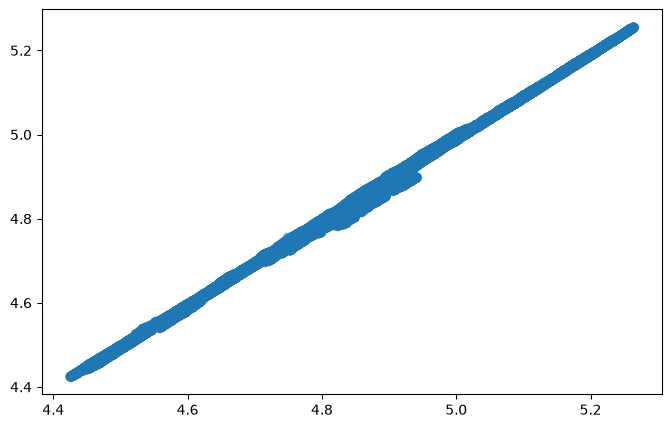

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.5, label="Prices of GOOG vs GOOGL")



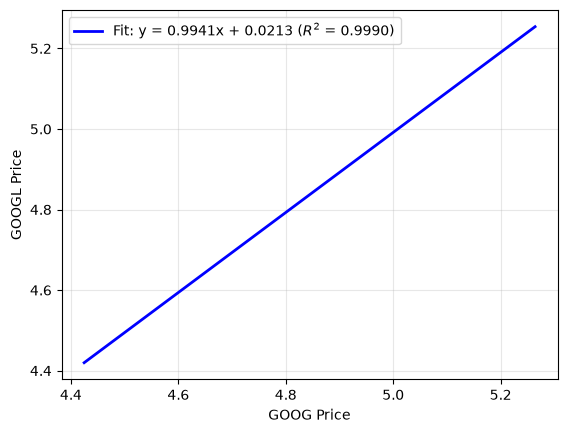

In [15]:
sort_idx = np.argsort(x)
plt.plot(
    x[sort_idx],
    y_prediction[sort_idx],
    color = "blue",
    linewidth=2,
    label = f"Fit: y = {slope:.4f}x + {intercept:.4f} ($R^2$ = {r_squared:.4f})"
)
plt.xlabel("GOOG Price")
plt.ylabel('GOOGL Price')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

In [13]:
residual_spread = y - y_prediction
print(f"Residual spread: {residual_spread}")

Residual spread: [0.00137702 0.00162533 0.00160997 ... 0.00134644 0.00140171 0.00188486]


Testing Stationarity of Spread

In [46]:
residual_spread_adfuller = adfuller(residual_spread)

/var/folders/gt/q0sb8yms4xbc1pkxbrlk2f0w0000gp/T/ipykernel_11408/1395854958.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  residual_spread_adfuller = adfuller(residual_spread)


In [14]:
print(residual_spread_adfuller)

NameError: name 'residual_spread_adfuller' is not defined

Adfuller score < crit value = stationary data

In [57]:
print(f"Score: {residual_spread_adfuller[0]}")
print(f"P-value: {residual_spread_adfuller[1]}")
print(f"Used lags: {residual_spread_adfuller[2]}")
print(f"Observations: {residual_spread_adfuller[3]}")
print(f"Critical Values: {residual_spread_adfuller[4]}")

crit_values = residual_spread_adfuller[4]
print(crit_values)

if residual_spread_adfuller[0] < crit_values["1%"]:
   print("The spread is stationary with 99% certainty!")
elif residual_spread_adfuller[0] < crit_values["5%"]:
   print("The spread is stationary with 95% certainty!")
elif residual_spread_adfuller[0] < crit_values["10%"]:
   print("The spread is stationary with 90% certainty!")
else:
   print("The spread is non-stationary.")

Score: -4.789618503541232
P-value: 5.692823231914363e-05
Used lags: 80
Observations: 372809
Critical Values: {'1%': np.float64(-3.430367540738089), '5%': np.float64(-2.861547752793944), '10%': np.float64(-2.566774126530032)}
{'1%': np.float64(-3.430367540738089), '5%': np.float64(-2.861547752793944), '10%': np.float64(-2.566774126530032)}
The spread is stationary with 99% certainty!


The spread between GOOG and GOOGL is stationary, so z-scores can be used to accurately determine mean reversion

Mean Reversion Half Life Calculation

In [15]:
residual_spread_series = pd.Series(residual_spread)

original half-life measurement = 423 minutes

In [16]:
def mean_reversion_half_life(spread: pd.Series) -> float:
    spread_lag = spread.shift(1)
    spread_diff = spread - spread_lag
    df = pd.DataFrame({"lag": spread_lag, "diff": spread_diff}).dropna()
    x = sm.add_constant(df["lag"])
    y = df["diff"]
    model = sm.OLS(y, x).fit()

    lam = model.params["lag"]

    half_life = -np.log(2) / lam 
    return half_life
mean_reversion_half_life(residual_spread_series)

np.float64(423.57612386466536)

New calculation result = 16 minutes

In [17]:
def mean_reversion_half_life(spread: pd.Series, window: int) -> float:
    spread_lag = spread.shift(1)
    spread_diff = spread - spread_lag
    df = pd.DataFrame({"lag": spread_lag, "diff": spread_diff}).dropna()
    x = sm.add_constant(df["lag"])
    y = df["diff"]
    model = sm.OLS(y, x).fit()

    lam = model.params["lag"]

    half_life = -np.log(2) / lam 
    return half_life
rolling_mean = residual_spread_series.rolling(window=500).mean()
spread_deviation = residual_spread_series - rolling_mean
mean_reversion_half_life(spread_deviation, 500)


np.float64(16.811056740791564)

Mean Reversion half life is about 16 minutes

Z-Score Signal Generation

Z-score is how many standard deviations away from the mean a datapoint is 

In [18]:
rollingZ_score(prices["GOOG"], prices["GOOGL"], hedgeCoefficient=0.9941, window=500)



timestamp
2020-11-23 09:30:00-05:00         NaN
2020-11-23 09:31:00-05:00         NaN
2020-11-23 09:32:00-05:00         NaN
2020-11-23 09:33:00-05:00         NaN
2020-11-23 09:34:00-05:00         NaN
                               ...   
2024-11-20 15:55:00-05:00    0.228368
2024-11-20 15:56:00-05:00    0.034311
2024-11-20 15:57:00-05:00    0.027782
2024-11-20 15:58:00-05:00    0.161585
2024-11-20 15:59:00-05:00    1.315904
Length: 372890, dtype: float64

Below series should be blank for first 500, because of warmup calculation time set to 500 minutes

In [19]:
entry = 2 # std deviations from mean of spread between GOOG and GOOGL
exit = 0 # Reversion to mean
stop = 3.5 # Black Swan event

current_position: 0 = neutral, 1 = buy, -1 = sell

In [23]:
z = rollingZ_score(prices["GOOG"], prices["GOOGL"], slope, window=500)
z.rename("z-score")

timestamp
2020-11-23 09:30:00-05:00         NaN
2020-11-23 09:31:00-05:00         NaN
2020-11-23 09:32:00-05:00         NaN
2020-11-23 09:33:00-05:00         NaN
2020-11-23 09:34:00-05:00         NaN
                               ...   
2024-11-20 15:55:00-05:00    0.228385
2024-11-20 15:56:00-05:00    0.034413
2024-11-20 15:57:00-05:00    0.027868
2024-11-20 15:58:00-05:00    0.161594
2024-11-20 15:59:00-05:00    1.315319
Name: z-score, Length: 372890, dtype: float64

In [24]:
signals = signal_generator(z, entry, exit, stop)

In [25]:
signals

,Positions,Event
timestamp,,
2020-11-23 09:30:00-05:00,0,N/A
2020-11-23 09:31:00-05:00,0,N/A
2020-11-23 09:32:00-05:00,0,N/A
2020-11-23 09:33:00-05:00,0,N/A
2020-11-23 09:34:00-05:00,0,N/A
...,...,...
2024-11-20 15:55:00-05:00,0,N/A
2024-11-20 15:56:00-05:00,0,N/A
2024-11-20 15:57:00-05:00,0,N/A


In [21]:
print(f"Slope {slope}, intercept {intercept}")

Slope 0.9940650232687545, intercept 0.021259767429189662


Hedge ratio = 0.9940650232687545, intercept = 0.021259767429189662, z-score window = 500 minutes, entry point = 2 std deviations, exit point = 0 std deviation, 

In [80]:
bars, trades = portfolio_manager(signals, prices, slope, 10000, 390, time(15, 58), time(14, 58))

In [81]:
bars

,Side,GOOG Shares,GOOGL Shares,Equity
timestamp,,,,
2020-11-23 09:30:00-05:00,0,0.0,0.0,0.00000
2020-11-23 09:31:00-05:00,0,0.0,0.0,0.00000
2020-11-23 09:32:00-05:00,0,0.0,0.0,0.00000
2020-11-23 09:33:00-05:00,0,0.0,0.0,0.00000
2020-11-23 09:34:00-05:00,0,0.0,0.0,0.00000
...,...,...,...,...
2024-11-20 15:55:00-05:00,0,0.0,0.0,3520.54708
2024-11-20 15:56:00-05:00,0,0.0,0.0,3520.54708
2024-11-20 15:57:00-05:00,0,0.0,0.0,3520.54708


In [82]:
trades

,Side,Entry Time,Exit Time,Hold Bars,GOOG Shares,GOOGL Shares,GOOG Entry Price,GOOGL Entry Price,GOOG Exit Price,GOOGL Exit Price,PnL,Reason
0,-1,2020-11-24 12:12:00-05:00,2020-11-24 15:58:00-05:00,196,113.103314,-114.194359,87.890,87.570,88.42,88.130,-4.004085,End Of Day Close
1,1,2020-11-25 10:00:00-05:00,2020-11-25 10:08:00-05:00,7,-112.846523,114.012085,88.090,87.710,87.94,87.590,3.245528,Hit exit
2,1,2020-11-25 10:20:00-05:00,2020-11-25 11:10:00-05:00,43,-112.859335,114.012085,88.080,87.710,88.47,88.160,7.290298,Hit exit
3,1,2020-11-25 11:44:00-05:00,2020-11-25 12:32:00-05:00,37,-112.578145,113.713896,88.300,87.940,88.70,88.350,1.591439,Hit exit
4,1,2020-11-25 14:36:00-05:00,2020-11-25 14:41:00-05:00,4,-112.133674,113.275940,88.650,88.280,88.63,88.260,-0.022845,Hit exit
...,...,...,...,...,...,...,...,...,...,...,...,...
2237,-1,2024-11-18 11:41:00-05:00,2024-11-18 13:48:00-05:00,127,56.490596,-57.306590,175.970,174.500,175.81,174.310,1.849757,Hit exit
2238,-1,2024-11-18 14:57:00-05:00,2024-11-18 15:58:00-05:00,61,56.269955,-57.077626,176.660,175.200,176.59,175.130,0.056537,End Of Day Close
2239,-1,2024-11-19 09:45:00-05:00,2024-11-19 10:11:00-05:00,26,55.842899,-56.623538,178.011,176.605,176.80,175.290,6.834203,Hit exit
2240,-1,2024-11-19 11:19:00-05:00,2024-11-19 15:58:00-05:00,279,55.824396,-56.609114,178.070,176.650,179.63,178.225,-2.073297,End Of Day Close


In [83]:
win_rate = (trades["PnL"] > 0).sum() / trades["PnL"].count()
print(f"Winrate: {win_rate * 100}%")

Winrate: 63.1578947368421%


In [84]:
print(np.median(trades["PnL"]))

2.170411833221806


In [61]:
print(np.median(trades["Hold Bars"]))
print(np.mean(trades["Hold Bars"]))

23.0
57.56556645851918


In [ ]:
import os
from dotenv import load_dotenv
from data.data_loader import load_data
from datetime import datetime

In [54]:
load_dotenv("/Users/benjaminsumacbookm4/Desktop/Pairs Trading/.env")

True

In [55]:
ALPACA_SECRET_KEY = os.environ.get("ALPACA_SECRET_KEY")
ALPACA_PUBLIC_KEY = os.environ.get("ALPACA_PUBLIC_KEY")

In [56]:
load_data("GOOG", "GOOGL", ALPACA_SECRET_KEY, ALPACA_PUBLIC_KEY, datetime(2024, 11, 21), datetime(2026, 11, 21), "split")

,symbol,timestamp,close
0,GOOGL,2024-11-21 00:00:00+00:00,5.172187
1,GOOGL,2024-11-21 00:03:00+00:00,5.172187
2,GOOGL,2024-11-21 00:05:00+00:00,5.172074
3,GOOGL,2024-11-21 00:08:00+00:00,5.172956
4,GOOGL,2024-11-21 00:14:00+00:00,5.170484
...,...,...,...
746344,GOOG,2026-11-20 23:56:00+00:00,5.593968
746345,GOOG,2026-11-20 23:57:00+00:00,5.593484
746346,GOOG,2026-11-20 23:58:00+00:00,5.593707
746347,GOOG,2026-11-20 23:59:00+00:00,5.594677


In [327]:
from src.backtest import apply_cost

In [328]:
finra_regulatory_cost = 1.95
sec_regulatory_cost = 0.206

In [329]:
trade_cost=0.005

In [317]:
net = apply_cost(sec_regulatory_cost, finra_regulatory_cost, trade_cost, trades)

In [318]:
net

,Side,Entry Time,Exit Time,Hold Bars,GOOG Shares,GOOGL Shares,GOOG Entry Price,GOOGL Entry Price,GOOG Exit Price,GOOGL Exit Price,PnL,Reason,Net Pnl,Cost
0,-1,2020-11-30 09:34:00-05:00,2020-11-30 09:35:00-05:00,1,111.604920,-112.739572,89.0700,88.700,88.8800,88.5700,-6.548791,Hit exit,-12.673646,6.124855
1,-1,2020-11-30 09:40:00-05:00,2020-11-30 09:43:00-05:00,3,112.007327,-113.045444,88.7500,88.460,88.6500,88.3300,3.495175,Hit exit,-2.638708,6.133883
2,-1,2020-12-11 09:34:00-05:00,2020-12-11 09:36:00-05:00,2,112.654694,-113.623452,88.2400,88.010,88.2000,87.8000,19.354737,Hit exit,13.209080,6.145657
3,1,2020-12-11 09:55:00-05:00,2020-12-11 09:57:00-05:00,2,-112.146325,113.378685,88.6400,88.200,88.4700,88.1400,12.262154,Hit exit,6.123496,6.138658
4,-1,2020-12-16 09:34:00-05:00,2020-12-16 14:21:00-05:00,250,112.539910,-113.649278,88.3300,87.990,87.8600,87.5300,-0.615090,Hit exit,-6.744877,6.129787
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,-1,2024-08-27 10:21:00-04:00,2024-08-27 11:56:00-04:00,95,59.301070,-60.289995,167.6302,165.865,167.5300,165.7200,2.800082,Hit exit,-2.281372,5.081454
111,-1,2024-09-23 09:45:00-04:00,2024-09-23 09:54:00-04:00,9,60.191645,-60.942166,165.1500,164.090,165.3900,164.2600,4.085827,Hit exit,-1.018760,5.104587
112,1,2024-09-25 09:31:00-04:00,2024-09-25 09:32:00-04:00,1,-60.797597,61.648480,163.5040,162.210,163.3800,162.0300,-3.557824,Hit exit,-8.667096,5.109271
113,1,2024-10-17 09:39:00-04:00,2024-10-17 11:14:00-04:00,95,-59.717952,60.661207,166.4600,164.850,165.3729,163.8700,5.471402,Hit exit,0.403416,5.067986


In [330]:
z = rollingZ_score(prices["GOOG"], prices["GOOGL"], slope, window=500)
z.rename("z-score")

timestamp
2020-11-23 09:30:00-05:00         NaN
2020-11-23 09:31:00-05:00         NaN
2020-11-23 09:32:00-05:00         NaN
2020-11-23 09:33:00-05:00         NaN
2020-11-23 09:34:00-05:00         NaN
                               ...   
2024-11-20 15:55:00-05:00    0.228385
2024-11-20 15:56:00-05:00    0.034413
2024-11-20 15:57:00-05:00    0.027868
2024-11-20 15:58:00-05:00    0.161594
2024-11-20 15:59:00-05:00    1.315319
Name: z-score, Length: 372890, dtype: float64

In [345]:
entry = 2 # std deviations from mean of spread between GOOG and GOOGL
exit = 0 # Reversion to mean
stop = 5 # Black Swan event

In [346]:
signals = signal_generator(z, entry, exit, stop)

In [357]:
bars, trades = portfolio_manager(signals, prices, slope, 10000, 390, time(15, 58), time(10, 58))

In [ ]:
trade_cost=0.005

In [359]:
finra_regulatory_cost = 1.95
sec_regulatory_cost = 0.206

In [360]:
net = apply_cost(sec_regulatory_cost, finra_regulatory_cost, trade_cost, trades)

In [361]:
win_rate = (net["Net Pnl"] > 0).sum() / net["Net Pnl"].count()
print(f"Winrate: {win_rate * 100}%")

Winrate: 55.55555555555556%
